In [1]:
# There are no publically available clavicle segmentation datasets that segment the entire clavicle

# This analysis uses a image and segmentation from a research paper figure to evaluate
# how well the chestx_det model is at segmenting clavicles.
# https://onlinelibrary.wiley.com/doi/10.1155/2020/2785464

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import skimage
import torch
import torchvision
import matplotlib.pyplot as plt
import torchxrayvision as xrv

In [4]:
img = skimage.io.imread("../../../torchxrayvision-main/images/00000001_000.png")

In [5]:
img.shape

(1024, 1024)

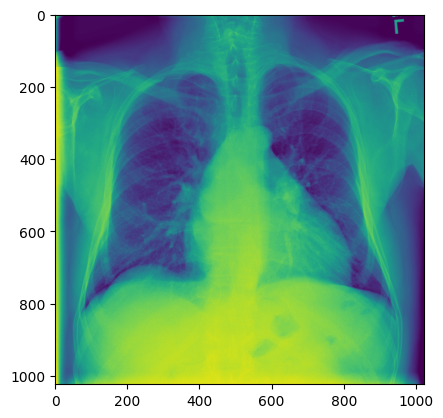

In [6]:
plt.imshow(img);

In [7]:
seg_gt = skimage.io.imread("../../../torchxrayvision-main/images/00000001_000.png")

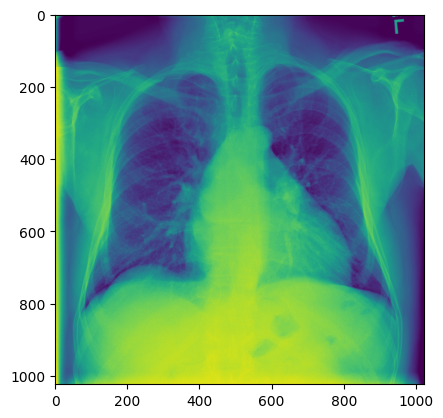

In [8]:
plt.imshow(seg_gt);

In [9]:
seg_gt.shape

(1024, 1024)

In [10]:
seg_gt[:20, :] = 0
seg_gt[:, -20:] = 0
seg_gt[-20:, :] = 0
seg_gt[:, :20] = 0

In [11]:
seg_gt = (seg_gt[:,:,0] > 100)

IndexError: too many indices for array: array is 2-dimensional, but 3 were indexed

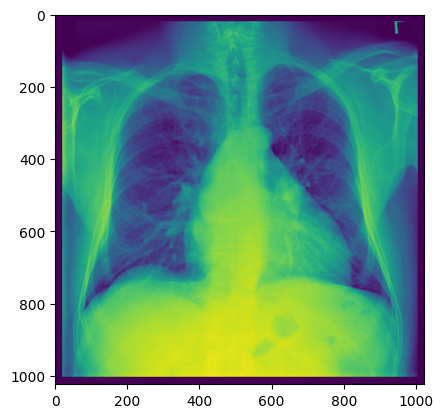

In [ ]:
plt.imshow(seg_gt);

In [ ]:
model = xrv.baseline_models.chestx_det.PSPNet()

In [ ]:
model

chestx-det-pspnet

In [ ]:
img = xrv.datasets.normalize(img, 255) # convert 8-bit image to [-1024, 1024] range
img = img.mean(2)[None, ...] # Make single color channel

transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop()])

img = transform(img)
img = torch.from_numpy(img)

AxisError: axis 2 is out of bounds for array of dimension 2

In [ ]:
seg_gt = transform(seg_gt[None,...])

NameError: name 'transform' is not defined

In [ ]:
img.shape

torch.Size([1, 498, 498])

In [ ]:
with torch.no_grad():
    pred = model(img)

In [ ]:
pred.shape

torch.Size([1, 14, 512, 512])

In [ ]:
pred = torch.nn.functional.interpolate(pred, size=[498, 498])

In [ ]:
pred.shape

torch.Size([1, 14, 498, 498])

TypeError: Invalid shape (1024,) for image data

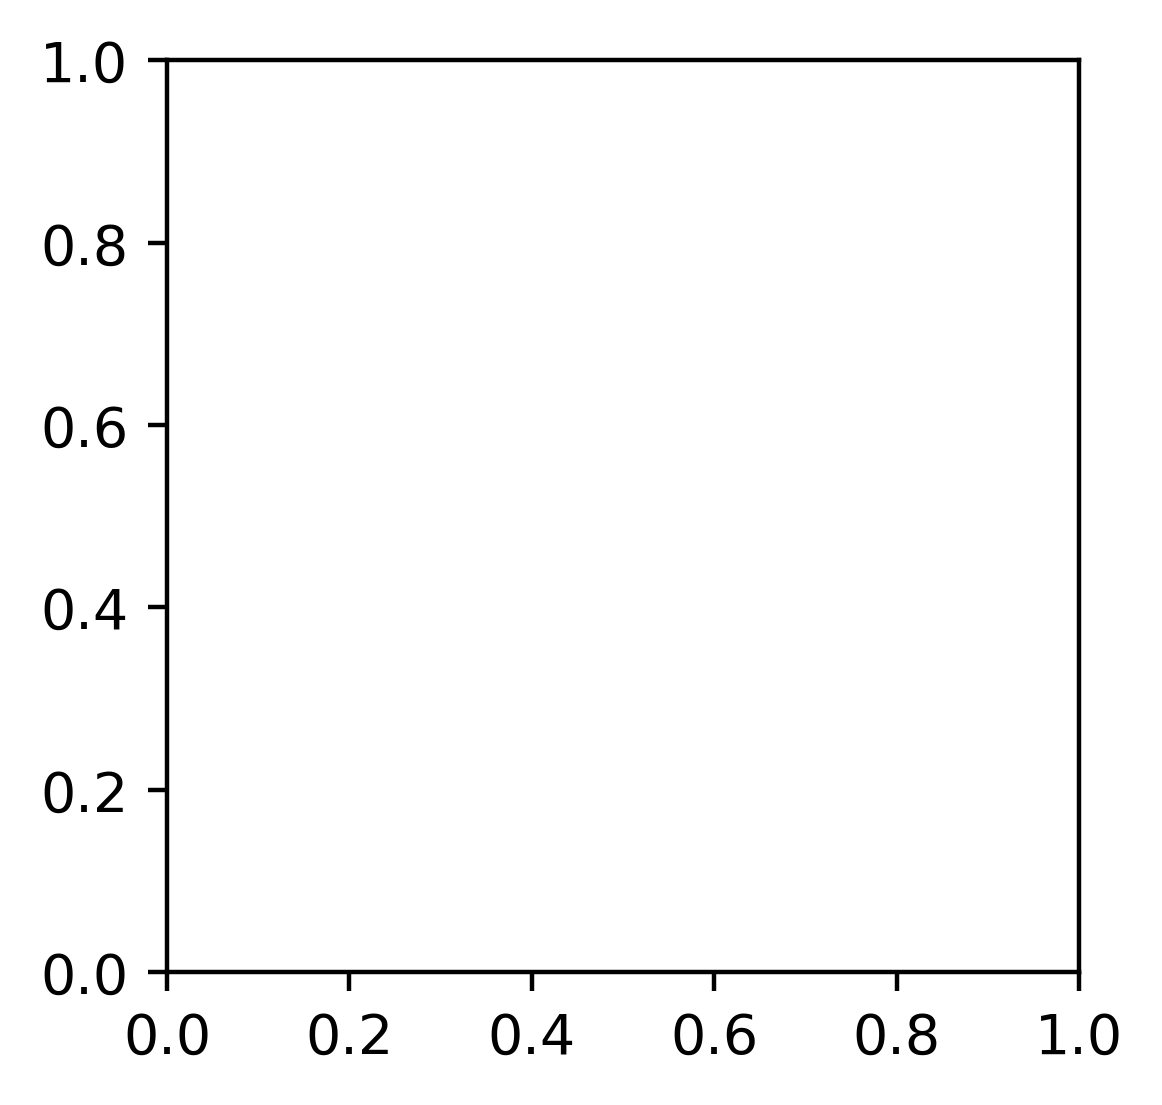

In [ ]:
plt.figure(figsize = (10,5), dpi=400)
plt.subplot(1, 3, 1)
plt.imshow(img[0], cmap='gray')
for i in range(2):
    plt.subplot(1, 3, i+2)
    plt.imshow(pred[0, i])
    plt.title(model.targets[i])
    plt.axis('off')
plt.tight_layout()

In [ ]:
pred = 1 / (1 + np.exp(-pred))  # sigmoid
pred[pred < 0.5] = 0
pred[pred > 0.5] = 1

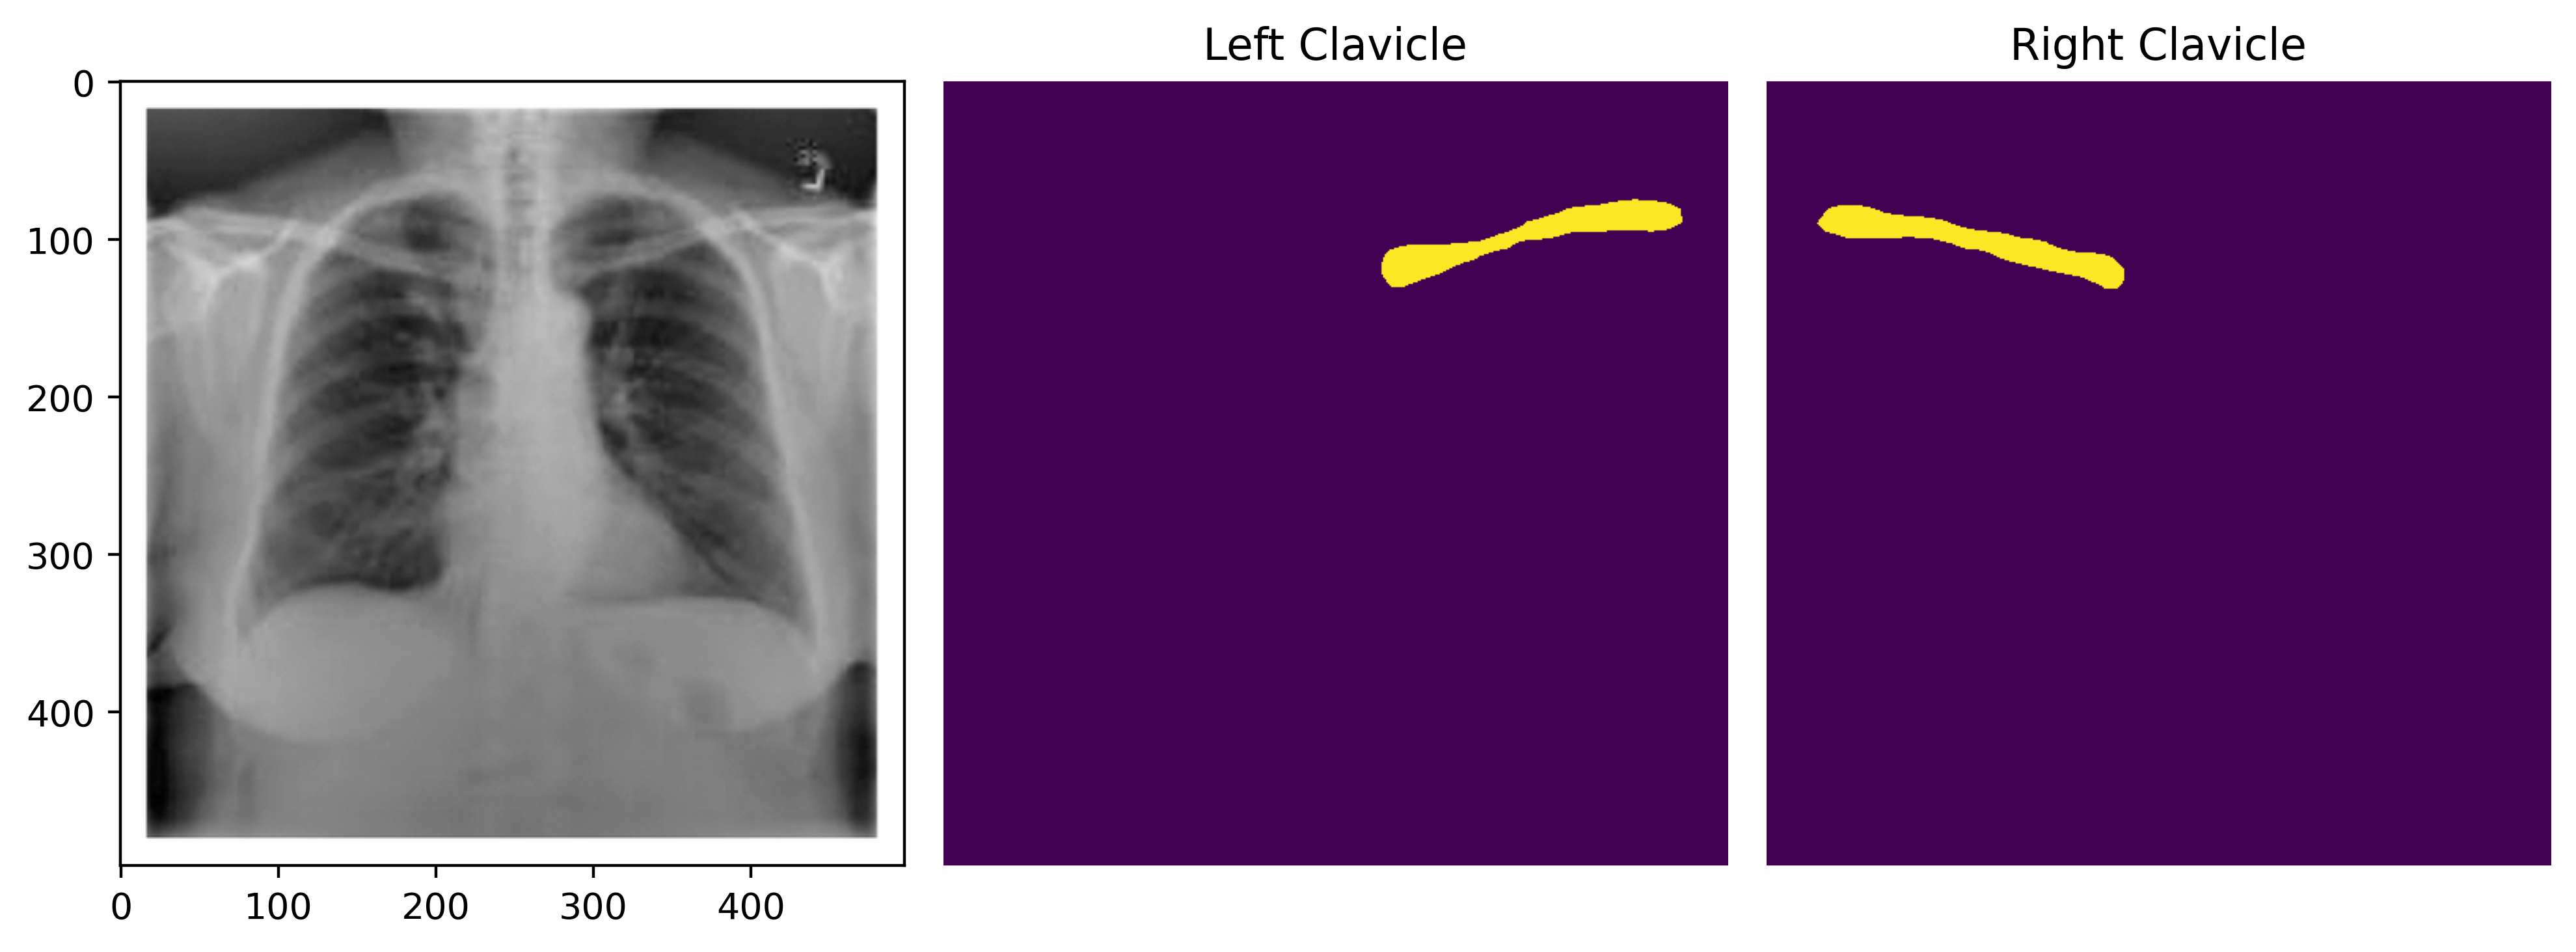

In [ ]:
plt.figure(figsize = (10,5), dpi=400)
plt.subplot(1, 3, 1)
plt.imshow(img[0], cmap='gray')
for i in range(2):
    plt.subplot(1, 3, i+2)
    plt.imshow(pred[0, i])
    plt.title(model.targets[i])
    plt.axis('off')
plt.tight_layout()

In [ ]:
pred_clavicles = torch.logical_or(pred[0,model.targets.index('Left Clavicle')],pred[0,model.targets.index('Right Clavicle')])

In [ ]:
pred_clavicles.shape

torch.Size([498, 498])

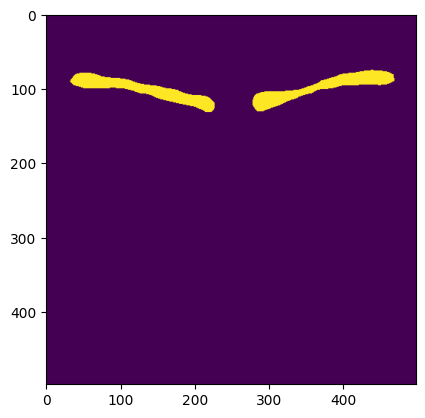

In [ ]:
plt.imshow(pred_clavicles);

In [ ]:
seg_gt.shape

(1, 498, 498)

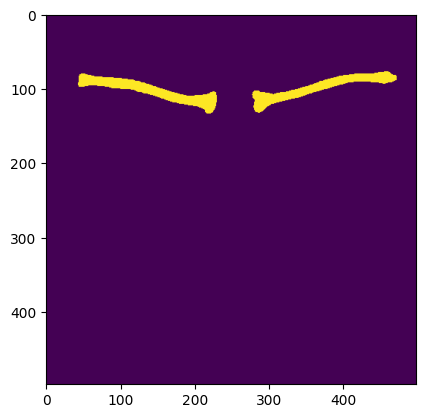

In [ ]:
plt.imshow(seg_gt[0]);

In [ ]:
torch.from_numpy(seg_gt[0]).flatten()

tensor([False, False, False,  ..., False, False, False])

In [ ]:
pred_clavicles.flatten()

tensor([False, False, False,  ..., False, False, False])

In [ ]:
def compute_iou(tensor1, tensor2, threshold=None):
    if threshold is not None:
        tensor1 = (tensor1 > threshold).float()
        tensor2 = (tensor2 > threshold).float()

    intersection = (tensor1 * tensor2).sum()
    union = ((tensor1 + tensor2) > 0).float().sum()

    if union == 0:
        return torch.tensor(1.0)  # Define IoU as 1 if both are completely empty
    else:
        return intersection / union
        

In [ ]:
compute_iou(torch.from_numpy(seg_gt[0]).flatten(),pred_clavicles.flatten())

tensor(0.7533)